# Notebook 07: Order Flow Imbalance and Price Changes

**Reference:** Cont, R., Kukanov, A. and Stoikov, S. (2014). The price impact of order book events. *Journal of Financial Econometrics*, 12(1), 47–88.

Cont, Kukanov and Stoikov measured the **order flow imbalance** (OFI) at the best quotes: lots added at the bid or taken from the ask count as buying pressure, lots added at the ask or taken from the bid as selling pressure. For consecutive book states $n-1 \to n$,

$$e_n = \mathbb{1}\{b_n \ge b_{n-1}\}\, q^b_n - \mathbb{1}\{b_n \le b_{n-1}\}\, q^b_{n-1} - \mathbb{1}\{a_n \le a_{n-1}\}\, q^a_n + \mathbb{1}\{a_n \ge a_{n-1}\}\, q^a_{n-1},$$

where $b, a$ are the best quotes and $q^b, q^a$ the depth there; the OFI of an interval is the sum of its $e_n$. In their data, mid-price changes over short intervals were close to linear in OFI, $\Delta P_k \approx \beta\,\mathrm{OFI}_k$, with a slope $\beta$ inversely proportional to the depth at the best quotes.

This notebook asks two questions of the simulator:
1. How much of the mid-price changes does OFI explain in each of Notebook 05's five models, with Notebook 05's parameters?
2. In the zero-intelligence model, does $\beta$ fall in proportion to $1/\text{depth}$ when the depth changes?

OFI is computed by `lob.metrics.order_flow_imbalance` from the simulation log's best quotes and the depth there (`bid_size`, `ask_size`); the dashboard's order-flow card computes the same quantity live.

In [1]:
import os
import sys
import warnings
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.hawkes import HawkesZIModel
from lob.models.mike_farmer import MikeFarmer2008Model, MikeFarmerModel
from lob.models.strategic import ParlourModel
from lob.metrics import order_flow_imbalance, ofi_regression
from lob.analysis.plotting import set_style

set_style()
pd.set_option('display.max_colwidth', None)

# Notebook 05's models and parameters.
ZI_PARAMS = dict(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000)
MODELS = {
    'ZI (Smith et al.)': lambda: SmithFarmerModel(**ZI_PARAMS),
    'ZI + Hawkes': lambda: HawkesZIModel(branching=0.8, decay=0.5, **ZI_PARAMS),
    'Mike-Farmer (simplified)': lambda: MikeFarmerModel(
        mu=1.0, lam=2.0, delta=0.05, alpha_price=1.5, hurst=0.7,
        initial_mid=10000, size_mean=0.5, size_sigma=0.3),
    'Mike-Farmer (2008 structure)': lambda: MikeFarmer2008Model(initial_mid=10000),
    'Parlour (Strategic)': lambda: ParlourModel(
        arrival_rate=5.0, delta=0.05, spread_threshold=5, depth_threshold=10, initial_mid=10000),
}
SEEDS = list(range(1, 9))
N_EVENTS = 200_000
K = 100  # events per interval

N_JOBS = min(8, os.cpu_count() or 1)
# joblib restarts a worker whose memory has grown by 300 MB and warns when it does; no work is lost.
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

## 1. OFI and Mid-Price Changes in Five Models

Each model runs for 200,000 events after warm-up with 8 seeds. The log is cut into intervals of $K$ = 100 events (Cont et al. used 10-second intervals; the simulation has no wall clock, so intervals are counted in events). For each run, the mid-price change of each interval is regressed on its OFI. The depth is the mean of the depths at the best bid and ask while both sides are quoted.

In [2]:
def measure(make_model, seed, n_events=N_EVENTS, k=K):
    reset_order_id_counter()
    sim = Simulation(model=make_model(),
                     config=SimulationConfig(n_events=n_events, warmup_events=5_000, seed=seed))
    df = sim.run(progress=False)
    e = order_flow_imbalance(df['best_bid'], df['bid_size'], df['best_ask'], df['ask_size'])
    mid = df['mid_price'].to_numpy()
    n = len(e) // k
    ofi = e[: n * k].reshape(n, k).sum(axis=1)
    dmid = mid[k: (n + 1) * k: k] - mid[: n * k: k]
    quoted = np.isfinite(dmid)
    fit = ofi_regression(ofi[quoted], dmid[quoted])
    both = (df['bid_size'] > 0) & (df['ask_size'] > 0)
    return {
        'beta': fit['beta'],
        'r2': fit['r2'],
        'depth': ((df['bid_size'] + df['ask_size']) / 2)[both].mean(),
        'moves': np.mean(dmid[quoted] != 0),
        'ofi': ofi[quoted],
        'dmid': dmid[quoted],
    }


tasks = [(name, seed) for name in MODELS for seed in SEEDS]
runs = Parallel(n_jobs=N_JOBS)(delayed(measure)(MODELS[name], seed) for name, seed in tasks)
results = {name: [run for (n, _), run in zip(tasks, runs, strict=True) if n == name] for name in MODELS}


def mean_ci(values):
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


rows = {}
for name, rs in results.items():
    beta, lo, hi = mean_ci([r['beta'] for r in rs])
    depth = np.mean([r['depth'] for r in rs])
    rows[name] = {
        'Slope β (ticks per lot)': f"{beta:.3f} (95% CI {lo:.3f} to {hi:.3f})",
        'R²': f"{np.mean([r['r2'] for r in rs]):.2f}",
        'Depth at the best quotes (lots)': f"{depth:.2f}",
        'β × depth': f"{beta * depth:.2f}",
        'Intervals with a price move': f"{np.mean([r['moves'] for r in rs]):.0%}",
    }
table = pd.DataFrame(rows).T
display(table)

,Slope β (ticks per lot),R²,Depth at the best quotes (lots),β × depth,Intervals with a price move
ZI (Smith et al.),0.129 (95% CI 0.123 to 0.134),0.28,2.85,0.37,34%
ZI + Hawkes,0.150 (95% CI 0.135 to 0.166),0.25,3.26,0.49,28%
Mike-Farmer (simplified),0.226 (95% CI 0.208 to 0.244),0.10,6.06,1.37,76%
Mike-Farmer (2008 structure),0.131 (95% CI 0.126 to 0.136),0.59,3.63,0.48,87%
Parlour (Strategic),0.245 (95% CI 0.242 to 0.248),0.61,2.16,0.53,90%


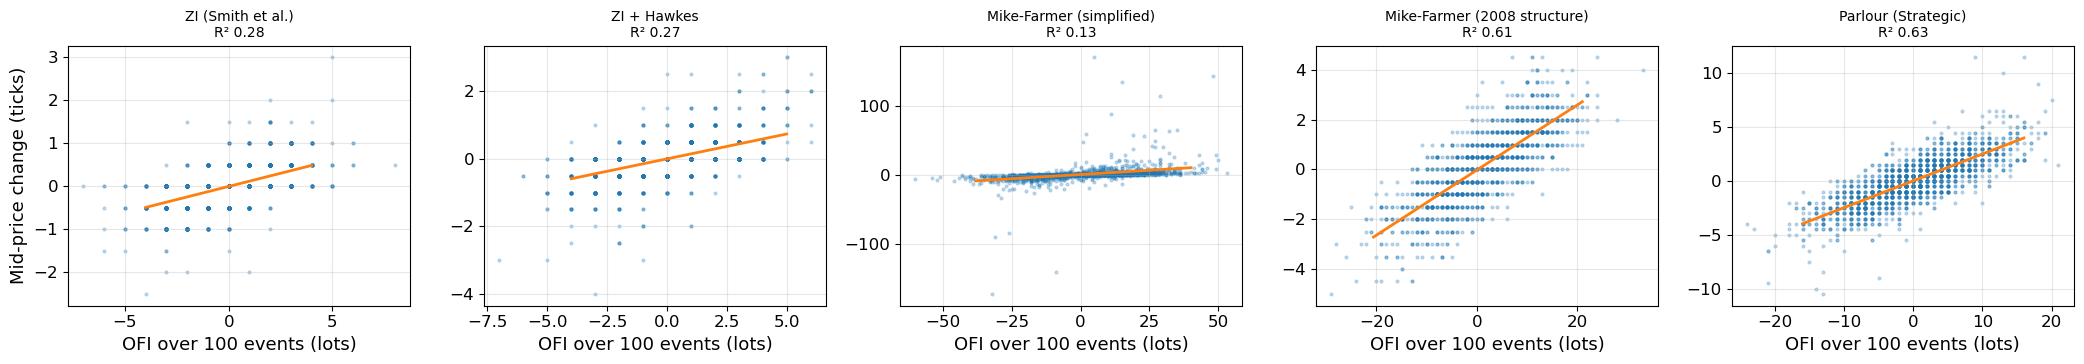

Share of the mid-price changes over 100 events that OFI explains (mean R² over seeds):
  Parlour (Strategic)            0.61
  Mike-Farmer (2008 structure)   0.59
  ZI (Smith et al.)              0.28
  ZI + Hawkes                    0.25
  Mike-Farmer (simplified)       0.10

OFI explains between 10% and 61% of the price changes, most in Parlour (Strategic) and least in Mike-Farmer (simplified).


In [3]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(4.2 * len(MODELS), 3.8), sharey=False)
for ax, (name, rs) in zip(axes, results.items(), strict=True):
    run = rs[0]
    ax.scatter(run['ofi'], run['dmid'], s=4, alpha=0.25)
    x = np.linspace(np.percentile(run['ofi'], 1), np.percentile(run['ofi'], 99), 2)
    fit = ofi_regression(run['ofi'], run['dmid'])
    ax.plot(x, fit['alpha'] + fit['beta'] * x, color='C1', linewidth=2)
    ax.set_title(f"{name}\nR² {fit['r2']:.2f}", fontsize=10)
    ax.set_xlabel('OFI over 100 events (lots)')
axes[0].set_ylabel('Mid-price change (ticks)')
plt.tight_layout()
plt.show()

order = sorted(results, key=lambda name: np.mean([r['r2'] for r in results[name]]), reverse=True)
r2 = {name: np.mean([r['r2'] for r in results[name]]) for name in order}
print("Share of the mid-price changes over 100 events that OFI explains (mean R² over seeds):")
for name in order:
    print(f"  {name:30s} {r2[name]:.2f}")
print(f"\nOFI explains between {min(r2.values()):.0%} and {max(r2.values()):.0%} of the price changes, "
      f"most in {order[0]} and least in {order[-1]}.")

## 2. Does the Slope Fall in Proportion to 1/Depth?

Cont et al. found the slope inversely proportional to the depth at the best quotes. In the zero-intelligence model the depth can be changed through the limit order rate $\lambda$ (more limit orders, deeper queues), keeping Notebook 05's other parameters. Above about $\lambda = 1$ the queues at the best quotes almost never empty within 100 events, so the sweep stays below that. If $\beta \propto 1/\text{depth}$, a log-log fit of $\beta$ on depth has slope $-1$.

In [4]:
LAMS = [0.15, 0.2, 0.3, 0.4, 0.5, 0.7]
sweep_tasks = [(lam, seed) for lam in LAMS for seed in SEEDS]
sweep_runs = Parallel(n_jobs=N_JOBS)(
    delayed(measure)(lambda lam=lam: SmithFarmerModel(**{**ZI_PARAMS, 'lam': lam}), seed)
    for lam, seed in sweep_tasks)
sweep = pd.DataFrame([{'lam': lam, 'beta': r['beta'], 'r2': r['r2'], 'depth': r['depth'], 'moves': r['moves']}
                      for (lam, _), r in zip(sweep_tasks, sweep_runs, strict=True)])
by_lam = sweep.groupby('lam').mean()
by_lam['β × depth'] = by_lam['beta'] * by_lam['depth']
display(by_lam.rename(columns={'beta': 'β', 'r2': 'R²', 'depth': 'depth', 'moves': 'intervals with a move'}).round(3))

# Fit over every run (not just the means), so the confidence interval reflects the run-to-run spread.
fit = stats.linregress(np.log(sweep['depth']), np.log(sweep['beta']))
half = stats.t.ppf(0.975, len(sweep) - 2) * fit.stderr
lo, hi = fit.slope - half, fit.slope + half
print(f"log β = {fit.intercept:.2f} + ({fit.slope:.2f}) log depth; 95% CI for the exponent {lo:.2f} to {hi:.2f}")
if lo <= -1 <= hi:
    print("The exponent is consistent with -1: β falls in proportion to 1/depth, as Cont et al. found.")
elif hi < -1:
    print(f"β falls faster than 1/depth: roughly as depth^{fit.slope:.1f}.")
else:
    print(f"β falls more slowly than 1/depth: roughly as depth^{fit.slope:.1f}.")

,β,R²,depth,intervals with a move,β × depth
lam,,,,,
0.15,0.605,0.549,1.457,0.865,0.881
0.20,0.441,0.505,1.635,0.783,0.720
0.30,0.275,0.418,2.002,0.614,0.551
0.40,0.185,0.349,2.402,0.463,0.444
0.50,0.129,0.275,2.853,0.337,0.368
0.70,0.061,0.145,3.847,0.164,0.233


log β = 0.35 + (-2.33) log depth; 95% CI for the exponent -2.38 to -2.28
β falls faster than 1/depth: roughly as depth^-2.3.


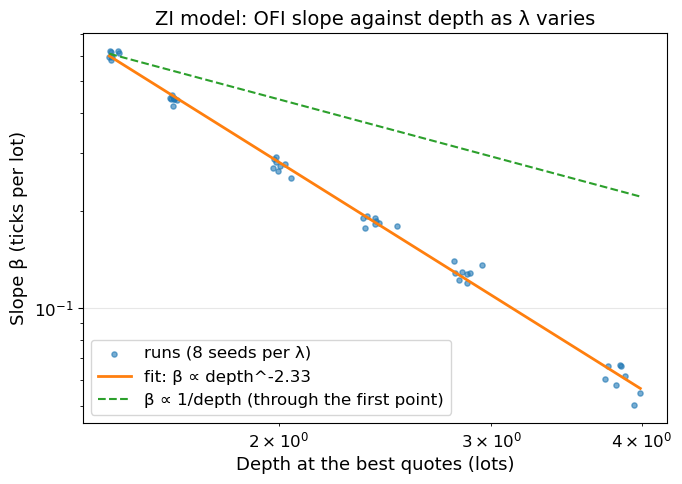

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(sweep['depth'], sweep['beta'], s=14, alpha=0.6, label='runs (8 seeds per λ)')
d = np.linspace(sweep['depth'].min(), sweep['depth'].max(), 50)
ax.plot(d, np.exp(fit.intercept) * d ** fit.slope, color='C1', linewidth=2, label=f'fit: β ∝ depth^{fit.slope:.2f}')
ax.plot(d, by_lam['beta'].iloc[0] * by_lam['depth'].iloc[0] / d, color='C2', linestyle='--',
        label='β ∝ 1/depth (through the first point)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Depth at the best quotes (lots)')
ax.set_ylabel('Slope β (ticks per lot)')
ax.set_title('ZI model: OFI slope against depth as λ varies')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Reading the Results

- The linear relation holds in every model: mid-price changes rise with OFI. How much of the price changes it explains differs by model, as the table and the summary above show.
- The comparison with Cont et al. is not like for like. They compared stocks and half-hours of real trading, where depth varies for many reasons. Raising $\lambda$ in the zero-intelligence model changes more than the depth at the best quote: the spread narrows, the depth behind the best quote grows and price moves become rarer (the last column of the sweep table). So the sweep tests the model, not the paper's claim, and whatever exponent it finds is a property of zero-intelligence order flow at these parameters.
- The dashboard's order-flow card measures the same relation live, on the session's own run, with the dashboard's parameters.